In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    r"E:\SEM5\ERA\ERA_Project\Brain_Tumor"
)

TRAIN_DIR = PROJECT_DIR / "data" / "Training"
TEST_DIR = PROJECT_DIR / "data" / "Testing"

MODEL_PATH = PROJECT_DIR / "models" / "resnet50_finetune.keras"

OUTPUT_DIR = PROJECT_DIR / "diagnostic_outputs" / "final_experiment"

GRADCAM_DIR = OUTPUT_DIR / "gradcam"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

IMG_SIZE = (224, 224)

# Generate Grad-CAM for this many images per class.
GRADCAM_IMAGES_PER_CLASS = 5

# Percentage of outer boundary to mask.
BORDER_FRACTION = 0.10

# IMPORTANT:
# Use the preprocessing method that was used during model training.
#
# "resnet"   = tf.keras.applications.resnet50.preprocess_input
# "rescale"  = pixel values divided by 255
#
PREPROCESS_MODE = "resnet"

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
print("Loading ResNet50 model...")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

model.summary()

print("\nModel loaded successfully.")

# Locate the nested ResNet50 backbone.
resnet_layer = model.get_layer("resnet50")

# Its output is the final spatial feature map.
print("ResNet50 output shape:", resnet_layer.output.shape)

# Build a model that returns:
# 1. Final ResNet50 feature maps
# 2. Final classification predictions

grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        resnet_layer.output,
        model.output
    ]
)

print("Grad-CAM model created.")

Loading ResNet50 model...


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 14,958,340 (57.06 MB)

 Non-trainable params: 9,163,136 (34.95 MB)


Model loaded successfully.
ResNet50 output shape: (None, 7, 7, 2048)
Grad-CAM model created.


In [3]:
def preprocess_image(image_array):

    image_array = image_array.astype(np.float32)

    if PREPROCESS_MODE == "resnet":

        image_array = tf.keras.applications.resnet50.preprocess_input(
            image_array
        )

    elif PREPROCESS_MODE == "rescale":

        image_array = image_array / 255.0

    else:
        raise ValueError("Invalid PREPROCESS_MODE")

    return image_array


def load_image(image_path):

    image = Image.open(image_path).convert("RGB")

    image = image.resize(
        IMG_SIZE,
        Image.Resampling.BILINEAR
    )

    original = np.asarray(image, dtype=np.uint8)

    processed = preprocess_image(original)

    return original, np.expand_dims(processed, axis=0)


def get_probabilities(output):

    output = np.asarray(output)

    # Handle either softmax probabilities or logits.
    if (
        np.all(output >= 0)
        and np.all(output <= 1)
        and np.allclose(output.sum(axis=1), 1.0, atol=1e-3)
    ):
        return output

    return tf.nn.softmax(output, axis=1).numpy()


def get_prediction(image_batch):

    output = model.predict(
        image_batch,
        verbose=0
    )

    probabilities = get_probabilities(output)

    predicted_index = np.argmax(probabilities[0])

    return (
        CLASS_NAMES[predicted_index],
        float(probabilities[0][predicted_index]),
        probabilities[0]
    )

In [4]:
def generate_gradcam(image_batch, class_index):

    image_tensor = tf.convert_to_tensor(
        image_batch,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        feature_maps, predictions = grad_model(
            image_tensor,
            training=False
        )

        # Use the score of the predicted class.
        class_score = predictions[:, class_index]

    gradients = tape.gradient(
        class_score,
        feature_maps
    )

    if gradients is None:
        raise RuntimeError(
            "Could not calculate Grad-CAM gradients. "
            "Check the model architecture."
        )

    # Global average pooling of gradients.
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    feature_maps = feature_maps[0]

    # Weighted combination of feature maps.
    heatmap = tf.reduce_sum(
        feature_maps * pooled_gradients,
        axis=-1
    )

    # Retain positive activations.
    heatmap = tf.maximum(heatmap, 0)

    # Normalize.
    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()


def save_gradcam(image, heatmap, save_path):

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 2, 2)

    plt.imshow(image)
    plt.imshow(
        heatmap,
        cmap="jet",
        alpha=0.40,
        extent=(0, image.shape[1], image.shape[0], 0)
    )

    plt.title("ResNet50 Grad-CAM")
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.close()



In [13]:
# Get the nested ResNet50 model
resnet_layer = model.get_layer("resnet50")

# Reconstruct the forward graph and capture ResNet50 feature maps
x = model.input
feature_maps = None

for layer in model.layers:

    # Skip the input layer
    if isinstance(layer, tf.keras.layers.InputLayer):
        continue

    # Apply each layer in the original model
    x = layer(x)

    # Capture the output of the nested ResNet50
    if layer.name == "resnet50":
        feature_maps = x

if feature_maps is None:
    raise ValueError("Could not find ResNet50 feature maps.")

# Build the Grad-CAM model
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[feature_maps, x]
)

print("Grad-CAM model created successfully.")
print("Feature map shape:", grad_model.outputs[0].shape)
print("Prediction shape:", grad_model.outputs[1].shape)

Grad-CAM model created successfully.
Feature map shape: (None, 7, 7, 2048)
Prediction shape: (None, 4)


In [14]:
gradcam_records = []

print("Generating Grad-CAM heatmaps...")

for class_name in CLASS_NAMES:

    class_dir = TEST_DIR / class_name

    image_paths = sorted([
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp"
        }
    ])

    # Deterministic sample selection.
    rng = np.random.default_rng(42)

    selected_indices = rng.choice(
        len(image_paths),
        size=min(
            GRADCAM_IMAGES_PER_CLASS,
            len(image_paths)
        ),
        replace=False
    )

    selected_images = [
        image_paths[i] for i in selected_indices
    ]

    for image_path in selected_images:

        original, image_batch = load_image(image_path)

        predicted_class, confidence, probabilities = (
            get_prediction(image_batch)
        )

        predicted_index = CLASS_NAMES.index(predicted_class)

        heatmap = generate_gradcam(
            image_batch,
            predicted_index
        )

        heatmap = tf.image.resize(
            heatmap[..., np.newaxis],
            IMG_SIZE
        ).numpy().squeeze()

        output_path = (
            GRADCAM_DIR /
            f"{class_name}_{image_path.stem}_gradcam.png"
        )

        save_gradcam(
            original,
            heatmap,
            output_path
        )

        correct = predicted_class == class_name

        gradcam_records.append({
            "image": image_path.name,
            "true_class": class_name,
            "predicted_class": predicted_class,
            "confidence": confidence,
            "correct": correct,
            "gradcam_path": str(output_path)
        })

        print(
            f"{image_path.name} | "
            f"True: {class_name} | "
            f"Predicted: {predicted_class} | "
            f"Confidence: {confidence:.4f}"
        )


gradcam_df = pd.DataFrame(gradcam_records)

gradcam_df.to_csv(
    OUTPUT_DIR / "gradcam_results.csv",
    index=False
)

print("\nGrad-CAM generation completed.")
print(gradcam_df.head())


Generating Grad-CAM heatmaps...
Te-gl_376.jpg | True: glioma | Predicted: glioma | Confidence: 0.7961
Te-gl_257.jpg | True: glioma | Predicted: meningioma | Confidence: 0.9755
Te-gl_333.jpg | True: glioma | Predicted: glioma | Confidence: 0.9994
Te-gl_130.jpg | True: glioma | Predicted: meningioma | Confidence: 0.9833
Te-gl_255.jpg | True: glioma | Predicted: glioma | Confidence: 0.9567
Te-me_283.jpg | True: meningioma | Predicted: meningioma | Confidence: 0.9058
Te-me_164.jpg | True: meningioma | Predicted: meningioma | Confidence: 0.9937
Te-me_240.jpg | True: meningioma | Predicted: pituitary | Confidence: 0.8664
Te-aug-me_38.jpg | True: meningioma | Predicted: meningioma | Confidence: 0.9403
Te-me_162.jpg | True: meningioma | Predicted: meningioma | Confidence: 0.9996
Te-no_376.jpg | True: notumor | Predicted: notumor | Confidence: 0.9999
Te-no_257.jpg | True: notumor | Predicted: notumor | Confidence: 1.0000
Te-no_333.jpg | True: notumor | Predicted: notumor | Confidence: 0.9980
Te

In [7]:
def mask_image_background(image):

    masked = image.copy()

    height, width, _ = masked.shape

    border_y = int(height * BORDER_FRACTION)
    border_x = int(width * BORDER_FRACTION)

    # Estimate a neutral fill value from the central region.
    center = masked[
        border_y:height-border_y,
        border_x:width-border_x
    ]

    fill_value = np.median(
        center.reshape(-1, 3),
        axis=0
    )

    # Mask top and bottom borders.
    masked[:border_y, :, :] = fill_value
    masked[height-border_y:, :, :] = fill_value

    # Mask left and right borders.
    masked[:, :border_x, :] = fill_value
    masked[:, width-border_x:, :] = fill_value

    return masked

    

In [ ]:
comparison_records = []

print("Evaluating original and masked test images...")

for class_name in CLASS_NAMES:

    class_dir = TEST_DIR / class_name

    image_paths = sorted([
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp"
        }
    ])

    for image_path in image_paths:

        original, _ = load_image(image_path)

        # Original image prediction.
        original_batch = np.expand_dims(
            preprocess_image(original),
            axis=0
        )

        original_prediction, original_confidence, original_probs = (
            get_prediction(original_batch)
        )

        # Masked image prediction.
        masked = mask_image_background(original)

        masked_batch = np.expand_dims(
            preprocess_image(masked),
            axis=0
        )

        masked_prediction, masked_confidence, masked_probs = (
            get_prediction(masked_batch)
        )

        comparison_records.append({

            "image": image_path.name,

            "true_class": class_name,

            "original_prediction": original_prediction,
            "original_confidence": original_confidence,

            "masked_prediction": masked_prediction,
            "masked_confidence": masked_confidence,

            "original_correct": (
                original_prediction == class_name
            ),

            "masked_correct": (
                masked_prediction == class_name
            ),

            "prediction_changed": (
                original_prediction != masked_prediction
            ),

            "confidence_change": (
                masked_confidence - original_confidence
            )
        })

    print(f"Completed: {class_name}")


comparison_df = pd.DataFrame(comparison_records)

comparison_df.to_csv(
    OUTPUT_DIR / "background_masking_results.csv",
    index=False
)

print("\nBackground masking evaluation completed.")

Evaluating original and masked test images...
Completed: glioma
Completed: meningioma
Completed: notumor
Completed: pituitary

Background masking evaluation completed.


In [9]:
y_true = comparison_df["true_class"]

original_predictions = comparison_df["original_prediction"]
masked_predictions = comparison_df["masked_prediction"]

original_accuracy = accuracy_score(
    y_true,
    original_predictions
)

masked_accuracy = accuracy_score(
    y_true,
    masked_predictions
)

prediction_change_rate = (
    comparison_df["prediction_changed"].mean()
)

original_confidence = (
    comparison_df["original_confidence"].mean()
)

masked_confidence = (
    comparison_df["masked_confidence"].mean()
)

print("\n" + "=" * 65)
print("FINAL BACKGROUND MASKING RESULTS")
print("=" * 65)

print(f"\nOriginal Test Accuracy: {original_accuracy:.4f}")
print(f"Masked Test Accuracy:   {masked_accuracy:.4f}")

print(
    f"Accuracy Change: "
    f"{masked_accuracy - original_accuracy:+.4f}"
)

print(
    f"\nPrediction Change Rate: "
    f"{prediction_change_rate:.4f}"
)

print(
    f"Original Mean Confidence: "
    f"{original_confidence:.4f}"
)

print(
    f"Masked Mean Confidence: "
    f"{masked_confidence:.4f}"
)

print("\nOriginal Classification Report:")

print(
    classification_report(
        y_true,
        original_predictions,
        labels=CLASS_NAMES,
        zero_division=0
    )
)

print("\nMasked Classification Report:")

print(
    classification_report(
        y_true,
        masked_predictions,
        labels=CLASS_NAMES,
        zero_division=0
    )
)




FINAL BACKGROUND MASKING RESULTS

Original Test Accuracy: 0.7775
Masked Test Accuracy:   0.6687
Accuracy Change: -0.1088

Prediction Change Rate: 0.2275
Original Mean Confidence: 0.8881
Masked Mean Confidence: 0.8280

Original Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.39      0.56       400
  meningioma       0.65      0.80      0.72       400
     notumor       0.81      0.99      0.89       400
   pituitary       0.81      0.93      0.87       400

    accuracy                           0.78      1600
   macro avg       0.82      0.78      0.76      1600
weighted avg       0.82      0.78      0.76      1600


Masked Classification Report:
              precision    recall  f1-score   support

      glioma       0.89      0.45      0.59       400
  meningioma       0.58      0.69      0.63       400
     notumor       0.59      1.00      0.75       400
   pituitary       0.85      0.54      0.66       400

    accurac

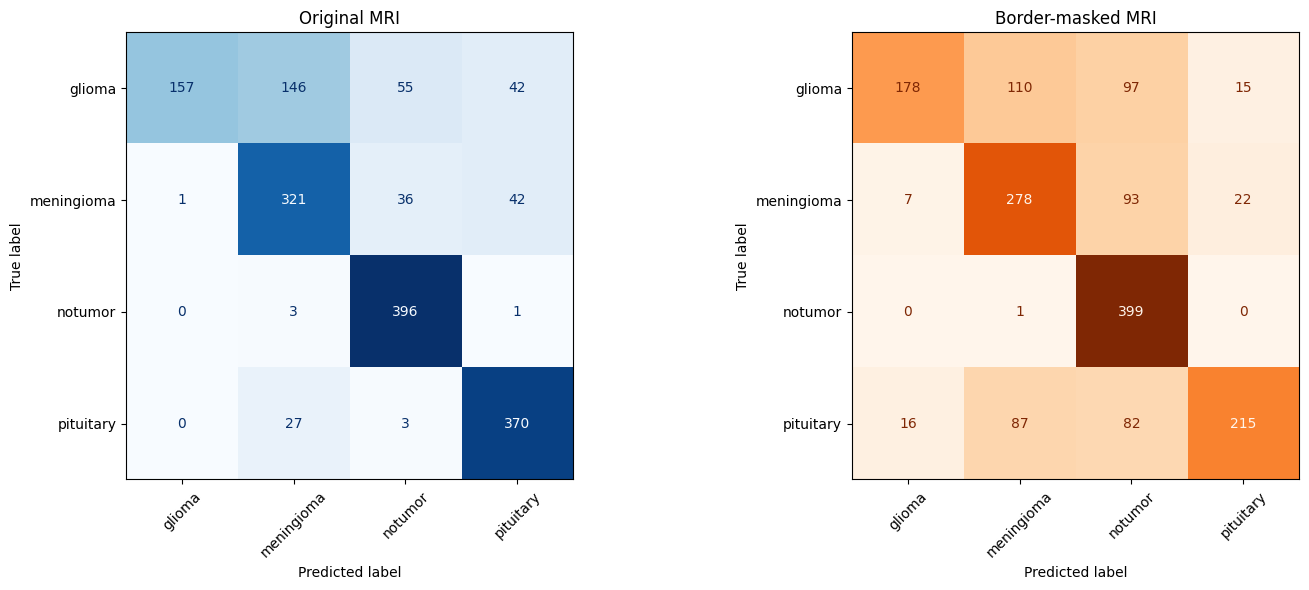

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cm_original = confusion_matrix(
    y_true,
    original_predictions,
    labels=CLASS_NAMES
)

cm_masked = confusion_matrix(
    y_true,
    masked_predictions,
    labels=CLASS_NAMES
)

ConfusionMatrixDisplay(
    cm_original,
    display_labels=CLASS_NAMES
).plot(
    ax=axes[0],
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

axes[0].set_title("Original MRI")

ConfusionMatrixDisplay(
    cm_masked,
    display_labels=CLASS_NAMES
).plot(
    ax=axes[1],
    cmap="Oranges",
    xticks_rotation=45,
    colorbar=False
)

axes[1].set_title("Border-masked MRI")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "original_vs_masked_confusion_matrix.png",
    dpi=300
)

plt.show()



CLASS-WISE RESULTS
     Class  Original Accuracy  Masked Accuracy  Prediction Change Rate  Original Confidence  Masked Confidence
    glioma             0.3925           0.4450                   0.275             0.792282           0.771840
meningioma             0.8025           0.6950                   0.210             0.874138           0.821711
   notumor             0.9900           0.9975                   0.010             0.990776           0.986570
 pituitary             0.9250           0.5375                   0.415             0.895342           0.732016


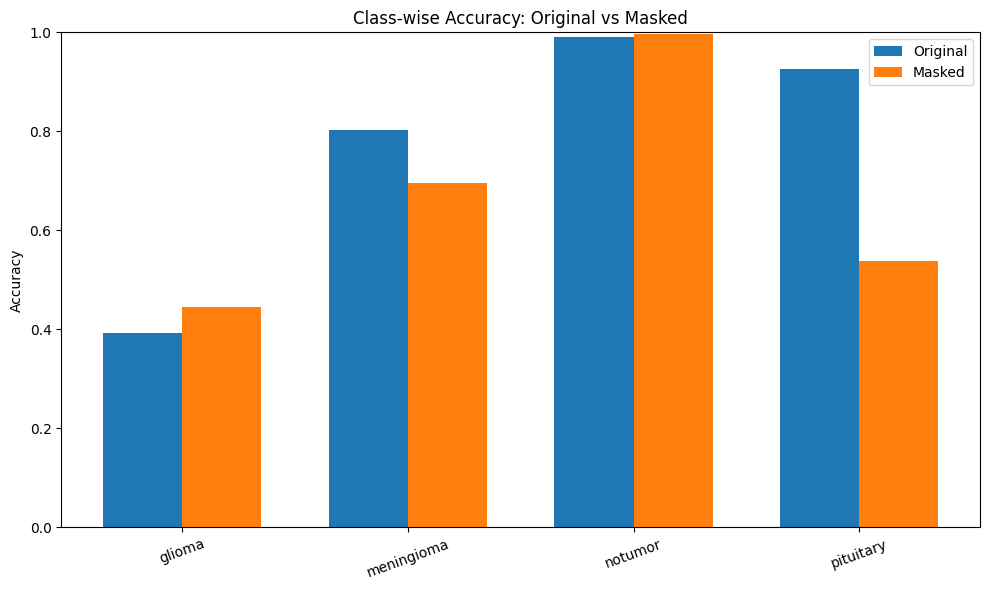

In [11]:
class_results = []

for class_name in CLASS_NAMES:

    subset = comparison_df[
        comparison_df["true_class"] == class_name
    ]

    class_results.append({

        "Class": class_name,

        "Original Accuracy": subset[
            "original_correct"
        ].mean(),

        "Masked Accuracy": subset[
            "masked_correct"
        ].mean(),

        "Prediction Change Rate": subset[
            "prediction_changed"
        ].mean(),

        "Original Confidence": subset[
            "original_confidence"
        ].mean(),

        "Masked Confidence": subset[
            "masked_confidence"
        ].mean()
    })


class_results_df = pd.DataFrame(class_results)

print("\nCLASS-WISE RESULTS")

print(
    class_results_df.to_string(index=False)
)

class_results_df.to_csv(
    OUTPUT_DIR / "class_wise_masking_results.csv",
    index=False
)


# Plot class-wise accuracy comparison.

x = np.arange(len(CLASS_NAMES))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    class_results_df["Original Accuracy"],
    width,
    label="Original"
)

plt.bar(
    x + width / 2,
    class_results_df["Masked Accuracy"],
    width,
    label="Masked"
)

plt.xticks(
    x,
    CLASS_NAMES,
    rotation=20
)

plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Class-wise Accuracy: Original vs Masked")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "class_wise_accuracy_comparison.png",
    dpi=300
)

plt.show()

In [12]:
print("\n" + "=" * 65)
print("BRAIN TUMOR DIAGNOSTIC EXPERIMENT COMPLETED")
print("=" * 65)

print("\nGrad-CAM images:", GRADCAM_DIR)

print("\nSaved results:")

for file in sorted(OUTPUT_DIR.iterdir()):

    print(file.name)

print("\nKey findings:")

print(
    f"Original accuracy: {original_accuracy:.4f}"
)

print(
    f"Masked accuracy: {masked_accuracy:.4f}"
)

print(
    f"Prediction change rate: {prediction_change_rate:.2%}"
)

print(
    f"Average confidence change: "
    f"{masked_confidence - original_confidence:+.4f}"
)


BRAIN TUMOR DIAGNOSTIC EXPERIMENT COMPLETED

Grad-CAM images: E:\SEM5\ERA\ERA_Project\Brain_Tumor\diagnostic_outputs\final_experiment\gradcam

Saved results:
background_masking_results.csv
class_wise_accuracy_comparison.png
class_wise_masking_results.csv
gradcam
original_vs_masked_confusion_matrix.png

Key findings:
Original accuracy: 0.7775
Masked accuracy: 0.6687
Prediction change rate: 22.75%
Average confidence change: -0.0601
